In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson

### 1. Carga, preparación de datos y selección de estación

In [2]:
df = pd.read_csv('contaminantes_N5//contaminantes_2026.csv')

params = ['O3', 'NO', 'NO2', 'NOX', 'CO']
df_filtered = df[df['id_parameter'].isin(params)]

# Pivotar para alinear parámetros por fecha y estación
piv = df_filtered.pivot_table(index=['date', 'id_station'], columns='id_parameter', values='valor').reset_index()

# Limpieza de nulos
data_all = piv.dropna(subset=params).copy()

# Conteo de datos por estación para elegir la que más tiene
station_counts = data_all['id_station'].value_counts()
print("Top 5 estaciones con más datos completos:")
print(station_counts.head())

# Seleccionamos la estación con mayor cantidad de datos (FAC)
best_station = station_counts.index[0]
data = data_all[data_all['id_station'] == best_station].copy()
print(f"\nEstación seleccionada: {best_station} con {len(data)} registros completos.")
data.head()

Top 5 estaciones con más datos completos:
id_station
FAC    1368
MGH    1367
HGM    1366
AJM    1350
MER    1283
Name: count, dtype: int64

Estación seleccionada: FAC con 1368 registros completos.


id_parameter,date,id_station,CO,NO,NO2,NOX,O3
7,2026-01-01 00:00:00,FAC,0.72,3.0,21.0,24.0,21.0
32,2026-01-01 01:00:00,FAC,0.71,6.0,24.0,30.0,14.0
57,2026-01-01 02:00:00,FAC,0.82,6.0,23.0,29.0,11.0
82,2026-01-01 03:00:00,FAC,0.74,7.0,23.0,30.0,11.0
107,2026-01-01 04:00:00,FAC,0.82,13.0,23.0,36.0,9.0


## a) Ajuste de Regresión Lineal para predecir O3


In [3]:
X = data[['NO', 'NO2', 'NOX', 'CO']]
X_const = sm.add_constant(X)
y = data['O3']

model = sm.OLS(y, X_const).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                     O3   R-squared:                       0.221
Model:                            OLS   Adj. R-squared:                  0.218
Method:                 Least Squares   F-statistic:                     96.43
Date:                Thu, 08 Oct 2026   Prob (F-statistic):           2.65e-72
Time:                        23:04:18   Log-Likelihood:                -6375.0
No. Observations:                1368   AIC:                         1.276e+04
Df Residuals:                    1363   BIC:                         1.279e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         37.6860      1.440     26.165      0.0

## b) Factor de Inflación de la Varianza (VIF)


In [4]:
vif_data = pd.DataFrame()
vif_data['Variable'] = X.columns
vif_data['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
vif_data

,Variable,VIF
0,NO,9162.080380
1,NO2,4944.758631
2,NOX,22430.920487
3,CO,28.437220


## c) Residuos vs Predichos y Prueba de Breusch-Pagan

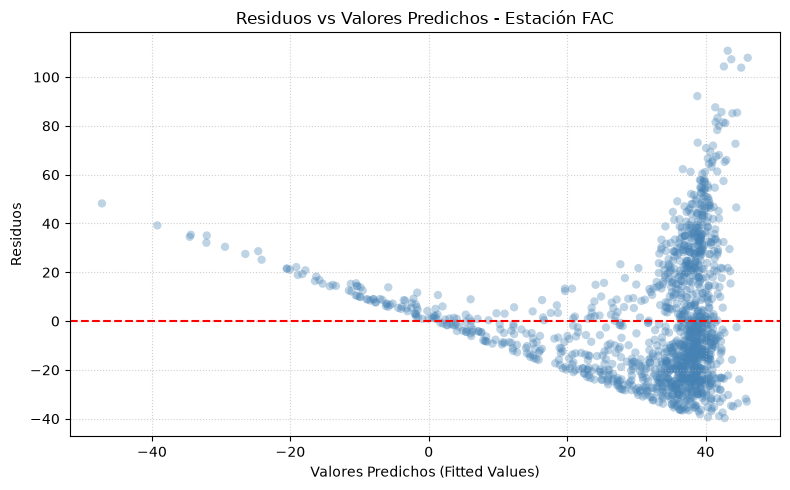

Breusch-Pagan LM Statistic: 85.5731
p-value: 1.1465e-17


In [5]:
# Gráfica Residuos vs Predichos
plt.figure(figsize=(8, 5))
plt.scatter(model.fittedvalues, model.resid, alpha=0.35, edgecolors='none', color='steelblue')
plt.axhline(0, color='red', linestyle='--', linewidth=1.5)
plt.xlabel('Valores Predichos (Fitted Values)')
plt.ylabel('Residuos')
plt.title(f'Residuos vs Valores Predichos - Estación {best_station}')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

# Prueba de Breusch-Pagan
bp_stat, bp_pval, _, _ = het_breuschpagan(model.resid, X_const)
print(f"Breusch-Pagan LM Statistic: {bp_stat:.4f}")
print(f"p-value: {bp_pval:.4e}")

## d) Residuos en el tiempo, promedio por hora del día y Durbin-Watson

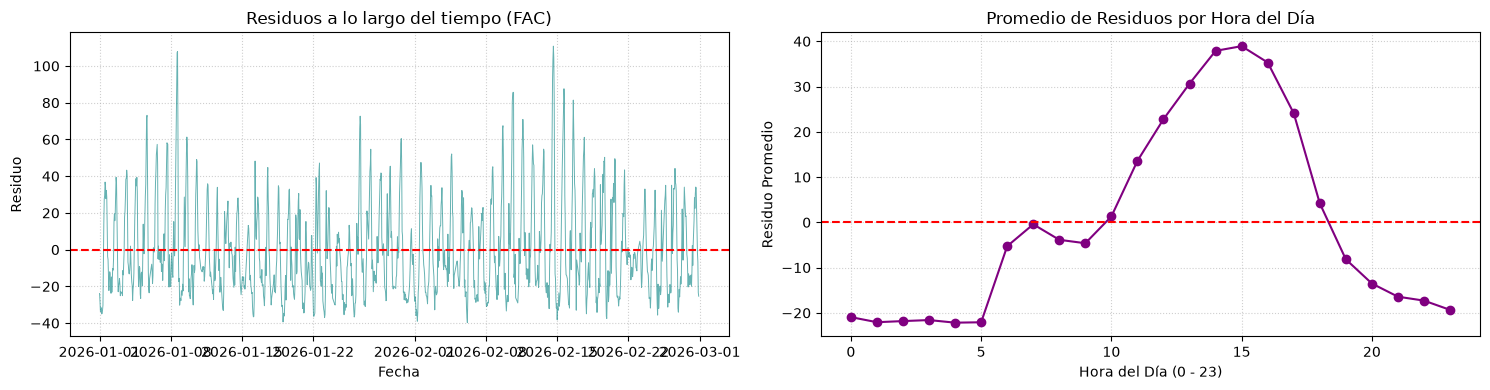

Durbin-Watson Statistic: 0.2405


In [6]:
data['resid'] = model.resid
data['date_dt'] = pd.to_datetime(data['date'])
data['hour'] = data['date_dt'].dt.hour
data_sorted = data.sort_values('date_dt')

fig, ax = plt.subplots(1, 2, figsize=(15, 4))

# 1. Residuos en el tiempo
ax[0].plot(data_sorted['date_dt'], data_sorted['resid'], alpha=0.6, linewidth=0.7, color='teal')
ax[0].axhline(0, color='red', linestyle='--')
ax[0].set_title(f'Residuos a lo largo del tiempo ({best_station})')
ax[0].set_xlabel('Fecha')
ax[0].set_ylabel('Residuo')
ax[0].grid(True, linestyle=':', alpha=0.6)

# 2. Promedio de residuos por hora del día
mean_resid_hour = data.groupby('hour')['resid'].mean()
ax[1].plot(mean_resid_hour.index, mean_resid_hour.values, marker='o', color='purple', linewidth=1.5)
ax[1].axhline(0, color='red', linestyle='--')
ax[1].set_title('Promedio de Residuos por Hora del Día')
ax[1].set_xlabel('Hora del Día (0 - 23)')
ax[1].set_ylabel('Residuo Promedio')
ax[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

# Estadístico Durbin-Watson
dw_stat = durbin_watson(data_sorted['resid'])
print(f"Durbin-Watson Statistic: {dw_stat:.4f}")

## e) Normal Q-Q Plot de los Residuos

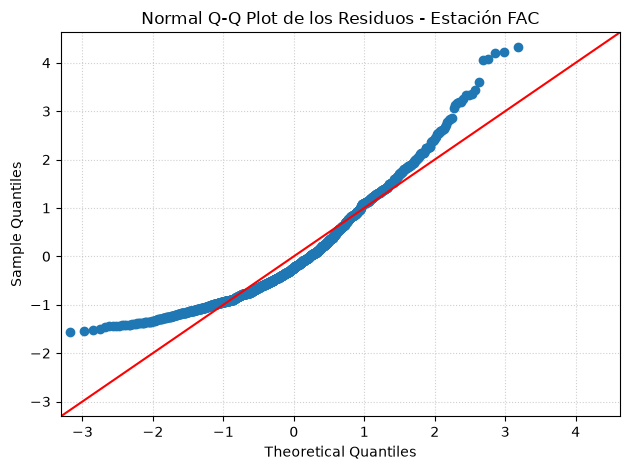

In [7]:
fig = sm.qqplot(model.resid, line='45', fit=True)
plt.title(f'Normal Q-Q Plot de los Residuos - Estación {best_station}')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()